In [3]:
'''
Для выполнения кластеризации я использую датасет из первой промежуточной аттестации.
Он содержит информацию о клиентах банка, их доходах, банковских продуктах и транзакционной активности.

Сначала загрузим данные в Pandas и посмотрим, какие столбцы есть в таблице и сколько в
ней наблюдений. Это поможет проверить, что файл загрузился правильно и его можно использовать для дальнейшего анализа.'''

'Загрузка данных\n\nДля выполнения кластеризации я использую датасет из первой промежуточной аттестации. \nОн содержит информацию о клиентах банка, их доходах, банковских продуктах и транзакционной активности.\n\nСначала загрузим данные в Pandas и посмотрим, какие столбцы есть в таблице и сколько в \nней наблюдений. Это поможет проверить, что файл загрузился правильно и его можно использовать для дальнейшего анализа.'

In [4]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_features.csv to customer_churn_features.csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("customer_churn_features.csv")

print("Размер датасета:", df.shape)

display(df.head())

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nТипы данных:")
df.info()

Размер датасета: (10000, 22)


,customer_id,age,gender,registration_date,annual_income,account_count,active_account_count,card_count,active_card_count,transaction_count,...,card_purchase_count,atm_withdrawal_count,transfer_out_count,utility_payment_count,transfer_count,loan_count,total_loan_amount,avg_interest_rate,last_transaction_date,churn
0,1,34,M,2025-07-12,455276.04,1,1,1,1,266,...,249,5,0,0,0,0,0.0,0.0,2026-01-27,0
1,2,54,M,2025-03-22,1945830.96,2,2,1,1,465,...,434,9,0,4,0,0,0.0,0.0,2026-01-26,0
2,3,18,F,2025-10-01,315794.16,1,1,1,1,155,...,144,2,1,1,1,0,0.0,0.0,2026-01-27,0
3,4,18,F,2025-11-22,647645.88,2,2,1,1,76,...,70,2,0,2,0,0,0.0,0.0,2026-01-25,0
4,5,49,M,2025-09-30,1061109.84,2,2,0,0,165,...,153,2,0,3,0,0,0.0,0.0,2026-01-27,0



Названия столбцов:
['customer_id', 'age', 'gender', 'registration_date', 'annual_income', 'account_count', 'active_account_count', 'card_count', 'active_card_count', 'transaction_count', 'total_transaction_amount', 'avg_transaction_amount', 'card_purchase_count', 'atm_withdrawal_count', 'transfer_out_count', 'utility_payment_count', 'transfer_count', 'loan_count', 'total_loan_amount', 'avg_interest_rate', 'last_transaction_date', 'churn']

Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   age                       10000 non-null  int64  
 2   gender                    10000 non-null  object 
 3   registration_date         10000 non-null  object 
 4   annual_income             10000 non-null  float64
 5   account_count             10000 non-null  in

In [ ]:
'''

Для кластеризации я выбрала пять признаков: возраст клиента, годовой доход, количество транзакций, среднюю сумму транзакции и количество кредитов.
Эти показатели позволяют рассмотреть клиентов с разных сторон: по возрасту, финансовым возможностям и активности использования банковских услуг.
Столбец customer_id не будем использовать, так как это просто идентификатор клиента.
Переменную churn также исключим из кластеризации, поскольку позже она понадобится для проверки того, отличаются ли полученные группы по уровню оттока.'''

In [6]:
features = [
    "age",
    "annual_income",
    "transaction_count",
    "avg_transaction_amount",
    "loan_count"
]

X = df[features].copy()

print("Выбранные признаки:")
print(X.head())

print("\nОсновная информация:")
print(X.info())

print("\nОписательная статистика:")
display(X.describe().round(2))

Выбранные признаки:
   age  annual_income  transaction_count  avg_transaction_amount  loan_count
0   34      455276.04                266             9241.079586           0
1   54     1945830.96                465             6387.733204           0
2   18      315794.16                155             2662.087419           0
3   18      647645.88                 76             2230.803289           0
4   49     1061109.84                165             6712.543576           0

Основная информация:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     10000 non-null  int64  
 1   annual_income           10000 non-null  float64
 2   transaction_count       10000 non-null  int64  
 3   avg_transaction_amount  10000 non-null  float64
 4   loan_count              10000 non-null  int64  
dtypes: float64(2)

,age,annual_income,transaction_count,avg_transaction_amount,loan_count
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,48.56,1628445.38,288.73,5948.75,0.29
std,18.06,1363651.83,134.43,4433.58,0.51
min,17.00,0.00,27.00,630.14,0.00
25%,33.00,589474.53,175.00,2259.89,0.00
50%,48.00,1237692.84,287.00,5173.85,0.00
75%,64.00,2156063.37,397.00,7267.99,1.00
max,80.00,9063431.40,620.00,25151.08,2.00


In [ ]:
'''Перед кластеризацией нужно масштабировать выбранные признаки. Они измеряются в разных единицах:
возраст — в годах, доход — в денежных единицах, а количество транзакций — в штуках.
Если использовать исходные значения, годовой доход может слишком сильно влиять на результат из-за большого
числового масштаба. Поэтому я применю стандартизацию с помощью StandardScaler. Она приводит признаки к сопоставимому масштабу,
чтобы каждый из них мог участвовать в формировании кластеров.'''

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Первые строки после масштабирования:")
display(X_scaled.head().round(2))

print("\nСредние значения признаков после масштабирования:")
print(X_scaled.mean().round(2))

print("\nСтандартные отклонения:")
print(X_scaled.std().round(2))

Первые строки после масштабирования:


,age,annual_income,transaction_count,avg_transaction_amount,loan_count
0,-0.81,-0.86,-0.17,0.74,-0.57
1,0.30,0.23,1.31,0.10,-0.57
2,-1.69,-0.96,-0.99,-0.74,-0.57
3,-1.69,-0.72,-1.58,-0.84,-0.57
4,0.02,-0.42,-0.92,0.17,-0.57



Средние значения признаков после масштабирования:
age                       0.0
annual_income            -0.0
transaction_count        -0.0
avg_transaction_amount    0.0
loan_count               -0.0
dtype: float64

Стандартные отклонения:
age                       1.0
annual_income             1.0
transaction_count         1.0
avg_transaction_amount    1.0
loan_count                1.0
dtype: float64


In [ ]:
'''Для разделения клиентов на группы я использую алгоритм K-Means.
Он объединяет наблюдения в кластеры так, чтобы клиенты внутри одной группы были максимально похожи друг на друга по выбранным признакам.

Заранее неизвестно, на сколько групп лучше разделить клиентов.
Поэтому я проверю несколько вариантов количества кластеров — от 2 до 10 — и сравню результаты
с помощью метода локтя. Этот метод помогает найти такое количество кластеров, после которого дальнейшее увеличение их числа даёт всё меньший эффект.'''

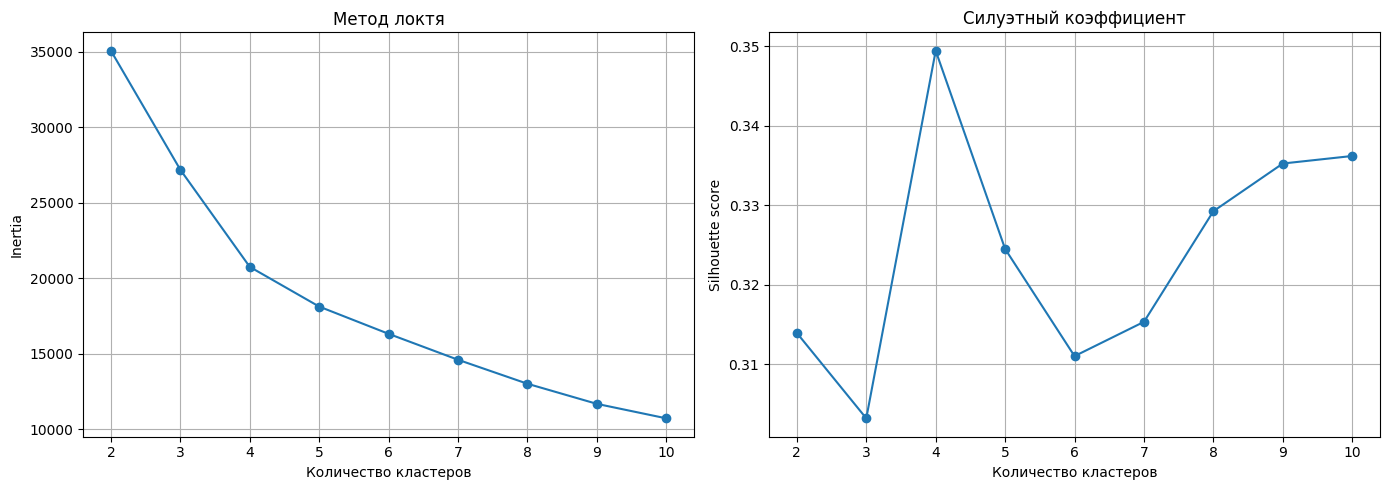

,Количество кластеров,Inertia,Silhouette score
0,2,35073.144,0.314
1,3,27189.628,0.303
2,4,20756.679,0.349
3,5,18126.469,0.325
4,6,16322.262,0.311
5,7,14604.314,0.315
6,8,13015.532,0.329
7,9,11683.637,0.335
8,10,10724.781,0.336


Лучший результат по силуэтному коэффициенту: 4 кластера


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )
    silhouette_values.append(score)

# Строим два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Количество кластеров")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="o"
)
axes[1].set_title("Силуэтный коэффициент")
axes[1].set_xlabel("Количество кластеров")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Выводим результаты в таблицу
results_kmeans = pd.DataFrame({
    "Количество кластеров": list(k_values),
    "Inertia": inertia_values,
    "Silhouette score": silhouette_values
})

display(results_kmeans.round(3))

print(
    "Лучший результат по силуэтному коэффициенту:",
    results_kmeans.loc[
        results_kmeans["Silhouette score"].idxmax(),
        "Количество кластеров"
    ],
    "кластера"
)

In [ ]:
'''значение 0,349 не означает идеального разделения, а говорит о том, что группы различаются, но между некоторыми клиентами из
 разных кластеров могут быть сходства'''

In [ ]:
'''

По результатам сравнения было выбрано 4 кластера.
Теперь обучим алгоритм K-Means с этим количеством групп и присвоим каждому клиенту номер кластера.

После этого посмотрим, сколько клиентов попало в каждую группу, и сравним средние значения выбранных признаков.
Это поможет понять, какие характеристики отличают клиентов из разных кластеров.'''

In [9]:
# Обучаем K-Means с четырьмя кластерами
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

# Количество клиентов в каждом кластере
print("Количество клиентов в кластерах:")
display(
    df["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("Количество клиентов")
    .to_frame()
)

# Средние значения признаков по кластерам
print("\nСредние значения признаков в каждом кластере:")
cluster_profile = df.groupby("kmeans_cluster")[features].mean().round(2)
display(cluster_profile)

# Доля клиентов с оттоком в каждом кластере
print("\nДоля оттока по кластерам, %:")
churn_by_cluster = (
    df.groupby("kmeans_cluster")["churn"]
    .mean()
    .mul(100)
    .round(2)
)
display(churn_by_cluster.rename("Доля оттока, %").to_frame())

Количество клиентов в кластерах:


,Количество клиентов
kmeans_cluster,
0,2091
1,3277
2,1473
3,3159



Средние значения признаков в каждом кластере:


,age,annual_income,transaction_count,avg_transaction_amount,loan_count
kmeans_cluster,,,,,
0,42.32,1762557.94,312.96,6858.39,1.12
1,68.49,663831.61,253.69,2702.06,0.01
2,48.22,4217297.28,322.00,14428.42,0.39
3,32.18,1333171.91,293.53,4760.67,0.00



Доля оттока по кластерам, %:


,"Доля оттока, %"
kmeans_cluster,
0,7.80
1,6.87
2,7.20
3,6.43


In [ ]:
'''- Кластер 0 — клиенты с кредитами. В среднем около 1,12 кредита на человека — больше, чем в остальных группах.
У них также сравнительно высокая средняя сумма транзакции.
- Кластер 1 — клиенты старшего возраста. Средний возраст — около 68 лет,
доход и средняя сумма транзакции ниже, чем в других группах. Кредиты практически отсутствуют.
- Кластер 2 — клиенты с высоким доходом и крупными транзакциями. У этой группы самые высокие средний доход и средняя сумма транзакции.
- Кластер 3 — молодые клиенты без кредитов. Средний возраст — около 32 лет, среднее количество кредитов равно нулю.

Что видно по оттоку
Самая высокая доля оттока у кластера 0 — 7,80%, а самая низкая у кластера 3 — 6,43%. Разница составляет 1,37 процентного пункта.
При этом различия небольшие. Похоже, что выбранные признаки хорошо помогают выделить группы по возрасту,
доходу и кредитам, но сами по себе не дают сильного разделения клиентов по оттоку.
Это нормально: K-Means группировал клиентов по выбранным признакам, а не пытался предсказывать отток.'''

In [ ]:
'''Для сравнения с K-Means применим иерархическую кластеризацию. Проверим три метода объединения объектов: Ward, complete и average.
Для ускорения расчётов используем выборку из 1 500 клиентов. Количество кластеров оставим равным четырем,
как и в K-Means. Сравним силуэтный коэффициент: чем он выше, тем лучше в среднем разделены кластеры и тем ближе объекты внутри своих групп.'''

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Берём одну и ту же выборку для всех методов
sample_idx = df.sample(n=1500, random_state=42).index
X_hier = X_scaled.loc[sample_idx]

# Метки K-Means для этой же выборки
kmeans_sample_labels = df.loc[sample_idx, "kmeans_cluster"]

linkage_methods = ["ward", "complete", "average"]
hierarchy_results = []
hierarchy_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=4,
        linkage=method
    )

    labels = model.fit_predict(X_hier)
    hierarchy_labels[method] = labels

    score = silhouette_score(X_hier, labels)
    ari = adjusted_rand_score(kmeans_sample_labels, labels)

    hierarchy_results.append({
        "Метод": method,
        "Silhouette score": round(score, 3),
        "ARI с K-Means": round(ari, 3)
    })

results_hierarchy = pd.DataFrame(hierarchy_results)
display(results_hierarchy)

# Размеры кластеров для каждого метода
for method, labels in hierarchy_labels.items():
    print(f"\nМетод: {method}")
    print(
        pd.Series(labels, name="Кластер")
        .value_counts()
        .sort_index()
        .to_frame("Количество клиентов")
    )

,Метод,Silhouette score,ARI с K-Means
0,ward,0.338,0.796
1,complete,0.150,0.227
2,average,0.302,0.489



Метод: ward
         Количество клиентов
Кластер                     
0                        566
1                        199
2                        437
3                        298

Метод: complete
         Количество клиентов
Кластер                     
0                        110
1                        657
2                        129
3                        604

Метод: average
         Количество клиентов
Кластер                     
0                        102
1                        296
2                        115
3                        987


In [ ]:
'''Ward: силуэтный коэффициент 0,338 — лучший среди трех методов. ARI 0,796 означает,
что разбиение довольно сильно похоже на результат K-Means на той же выборке.
Complete: результат слабее остальных по обеим метрикам. Силуэтный коэффициент 0,150 указывает,
что разделение кластеров получилось менее удачным.
Average: занимает промежуточное положение — результат лучше, чем у complete, но уступает Ward.'''

In [ ]:
'''Чтобы наглядно сравнить результаты двух алгоритмов, используем метод главных компонент (PCA).
Он позволяет отобразить данные с пятью признаками на плоскости,
сохранив как можно больше информации о различиях между клиентами.
Построим два графика для одной и той же выборки: первый покажет кластеры K-Means, второй —
кластеры иерархической кластеризации методом Ward. При интерпретации нужно учитывать, что на двумерном
графике могут быть не видны все различия между клиентами.'''

Две главные компоненты объясняют 63.87% разброса данных


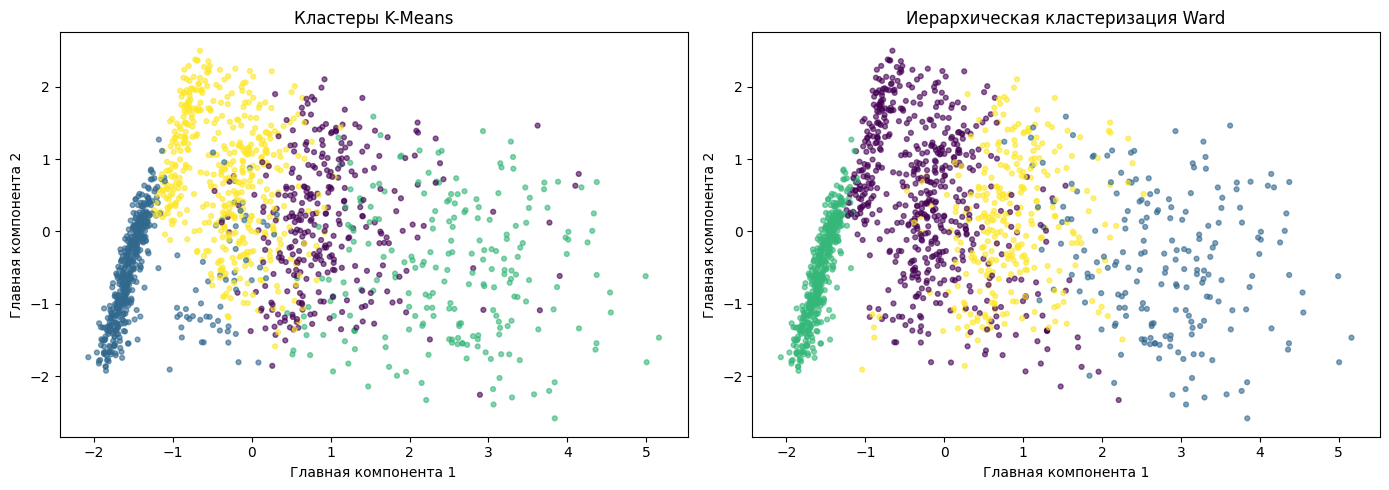

In [11]:
from sklearn.decomposition import PCA

# Преобразуем данные выборки в два измерения
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_hier)

# Сколько информации сохранили две главные компоненты
explained = pca.explained_variance_ratio_.sum() * 100
print(f"Две главные компоненты объясняют {explained:.2f}% разброса данных")

# Сравниваем два способа кластеризации на одной выборке
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.6
)
axes[0].set_title("Кластеры K-Means")
axes[0].set_xlabel("Главная компонента 1")
axes[0].set_ylabel("Главная компонента 2")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=hierarchy_labels["ward"],
    cmap="viridis",
    s=12,
    alpha=0.6
)
axes[1].set_title("Иерархическая кластеризация Ward")
axes[1].set_xlabel("Главная компонента 1")
axes[1].set_ylabel("Главная компонента 2")

plt.tight_layout()
plt.show()

In [ ]:
'''На графиках видно, что кластеры в целом различимы, хотя в некоторых областях точки разных групп пересекаются.
Это говорит о том, что клиенты отличаются по выбранным признакам, но некоторые из них имеют похожие
характеристики и поэтому попадают в соседние кластеры.
Две главные компоненты объясняют 63,87% разброса данных.
Поэтому графики помогают оценить структуру кластеров, но не отражают все различия между клиентами.'''

In [ ]:
'''На заключительном этапе сравним качество кластеризации разными методами.
Для K-Means используем лучший результат при четырёх кластерах, а для иерархической кластеризации
— результаты методов Ward, complete и average на выборке из 1 500 клиентов.

При сравнении учитываем силуэтный коэффициент и сходство с результатом K-Means.
Также помним, что K-Means обучался на всей базе, а иерархические методы — на выборке.'''

In [12]:
comparison = pd.DataFrame({
    "Метод": [
        "K-Means (k=4)",
        "Иерархический Ward",
        "Иерархический Complete",
        "Иерархический Average"
    ],
    "Silhouette score": [
        0.349,
        0.338,
        0.150,
        0.302
    ],
    "ARI с K-Means": [
        1.000,
        0.796,
        0.227,
        0.489
    ]
})

display(comparison.sort_values(
    by="Silhouette score",
    ascending=False
).reset_index(drop=True))

,Метод,Silhouette score,ARI с K-Means
0,K-Means (k=4),0.349,1.000
1,Иерархический Ward,0.338,0.796
2,Иерархический Average,0.302,0.489
3,Иерархический Complete,0.150,0.227


In [ ]:
'''## Итоговые выводы

В ходе работы была проведена кластеризация 10 000 клиентов банка. Для анализа выбрали пять признаков:
возраст, годовой доход, количество транзакций, среднюю сумму транзакции и количество кредитов.
Перед обучением алгоритмов признаки были стандартизированы, чтобы различия в масштабах значений не влияли на результат.
С помощью метода локтя и силуэтного коэффициента было выбрано четыре кластера для K-Means.
Силуэтный коэффициент составил 0,349 — это лучший результат среди рассмотренных вариантов.

Клиенты распределились на четыре группы. Первая группа характеризуется относительно большим количеством кредитов,
вторая — более старшим возрастом и низкой кредитной активностью, третья — высоким доходом и крупными транзакциями,
а четвёртая — более молодым возрастом и отсутствием кредитов в среднем.
Также была проведена иерархическая кластеризация тремя методами.
Лучший результат среди них показал Ward с силуэтным коэффициентом 0,338. Его разбиение было наиболее похоже на K-Means:
ARI составил 0,796. Методы average и complete показали более низкие значения метрик.

После сравнения кластеров с оттоком выяснилось, что его доля находится в диапазоне от 6,43% до 7,80%.
Самая высокая доля наблюдалась в кластере 0, а самая низкая — в кластере 3. Разница между группами есть,
но она небольшая, поэтому нельзя утверждать, что найденные кластеры сами по себе хорошо предсказывают уход клиентов.

Визуализация с помощью PCA показала, что две главные компоненты объясняют 63,87% разброса данных.
На графиках кластеры в целом различимы, но местами пересекаются.

Таким образом, для этой задачи K-Means оказался наиболее подходящим из рассмотренных методов по
илуэтному коэффициенту. Иерархическая кластеризация Ward дала близкий результат и может использоваться
для дополнительного сравнения. Полученные группы можно использовать как основу для дальнейшего изучения
клиентских сегментов и разработки разных подходов к работе с ними.'''